# Titanic Survival Prediction

**Goal:** Predict whether a passenger survived the Titanic disaster using passenger details (class, sex, age, fare, family size, port of embarkation).

**Dataset:** [Titanic - Machine Learning from Disaster (Kaggle)](https://www.kaggle.com/c/titanic) - `train.csv`, 891 passengers, 12 columns.

**Approach:**
1. Explore and clean the data
2. Visualise what influenced survival (EDA)
3. Build one preprocessing + model pipeline (imputation, encoding, scaling)
4. Compare Logistic Regression, Random Forest and K-Nearest Neighbors using 5-fold cross-validation
5. Tune the best model, evaluate on a held-out test set, inspect feature importance
6. Save the final model with pickle

## 1. Setup

In [1]:
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("train.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"Missing": missing, "Missing %": missing_pct})[missing > 0]

,Missing,Missing %
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


**Observations:** `Age` is missing for about 20% of passengers, `Embarked` for 2 passengers, and `Cabin` for about 77%. Cabin has too many gaps to impute reliably, so it will be dropped. Age and Embarked will be imputed inside the pipeline.

## 3. Exploratory data analysis

Overall survival rate: 38.4%


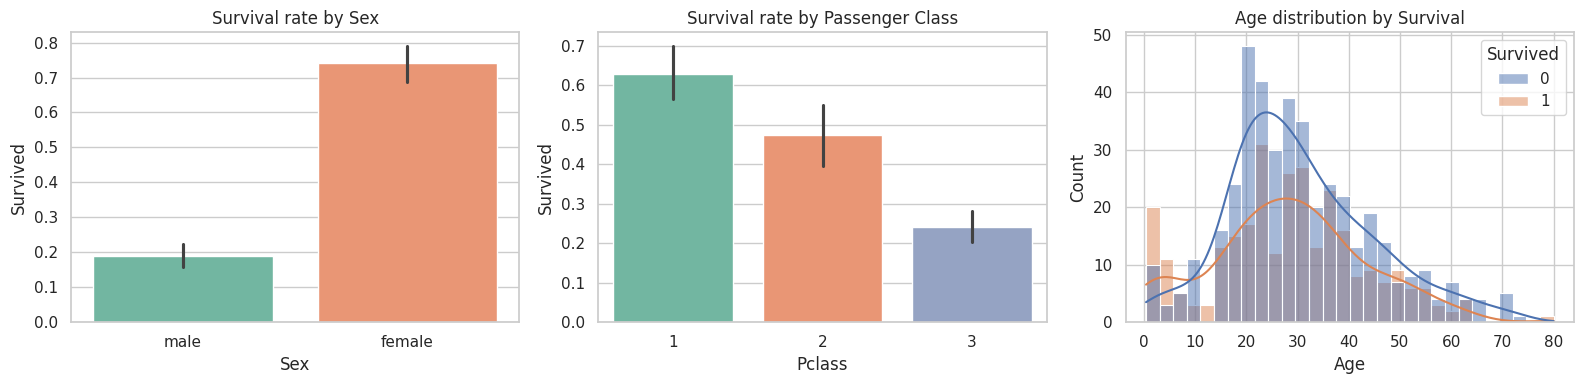

In [5]:
print(f"Overall survival rate: {df['Survived'].mean():.1%}")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0], palette="Set2")
axes[0].set_title("Survival rate by Sex")

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1], palette="Set2")
axes[1].set_title("Survival rate by Passenger Class")

sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[2])
axes[2].set_title("Age distribution by Survival")

plt.tight_layout()
plt.show()

**Observations:** Women survived at a much higher rate than men, first-class passengers survived more often than third-class passengers, and young children had comparatively better survival chances.

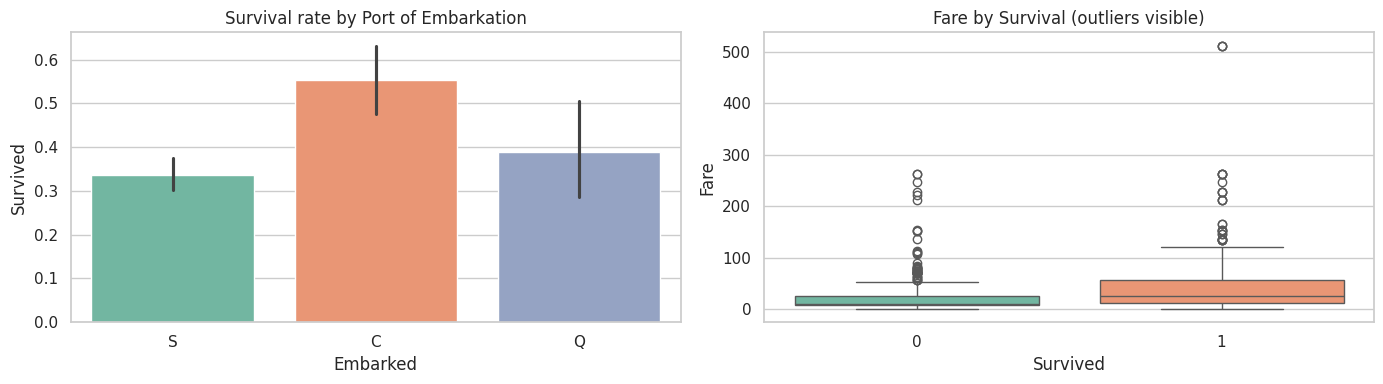

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=df, x="Embarked", y="Survived", ax=axes[0], palette="Set2")
axes[0].set_title("Survival rate by Port of Embarkation")

sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[1], palette="Set2")
axes[1].set_title("Fare by Survival (outliers visible)")

plt.tight_layout()
plt.show()

## 4. Outlier check (IQR method)

In [7]:
Q1, Q3 = df["Fare"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
n_out = ((df["Fare"] < lower) | (df["Fare"] > upper)).sum()
print(f"Fare valid range: [{lower:.2f}, {upper:.2f}]")
print(f"Outliers in Fare: {n_out} of {len(df)} ({n_out / len(df):.1%})")

Fare valid range: [-26.72, 65.63]
Outliers in Fare: 116 of 891 (13.0%)


Fare is right-skewed with some very expensive tickets. These are genuine first-class fares, not data errors, so they are **kept**. Standard scaling and tree-based models both handle them reasonably well.

## 5. Feature engineering and train/test split

Two simple engineered features:
- `FamilySize` = `SibSp` + `Parch` + 1
- `IsAlone` = 1 if the passenger travelled alone

`Cabin`, `Name`, `Ticket` and `PassengerId` are dropped (too many gaps or no predictive value in raw form).

The data is split **before** any imputation or scaling, so no information leaks from the test set into training.

In [8]:
data = df.copy()
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

features = ["Pclass", "Sex", "Age", "Fare", "Embarked", "FamilySize", "IsAlone"]
X = data[features]
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (712, 7) | Test: (179, 7)
Survival rate - train: 0.383, test: 0.385


## 6. Preprocessing pipeline

- **Numeric** (`Age`, `Fare`, `FamilySize`): median imputation, then standard scaling
- **Categorical** (`Pclass`, `Sex`, `Embarked`): most-frequent imputation, then one-hot encoding (`drop="first"` avoids redundant columns)
- **Binary** (`IsAlone`): passed through unchanged

In [9]:
num_cols = ["Age", "Fare", "FamilySize"]
cat_cols = ["Pclass", "Sex", "Embarked"]
bin_cols = ["IsAlone"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
    ("bin", "passthrough", bin_cols),
])

## 7. Model comparison with 5-fold cross-validation

Cross-validation gives a more reliable estimate than a single split. Each model sits in the same pipeline, so preprocessing is re-fitted inside every fold (no leakage).

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"Model": name, "Mean CV Accuracy": scores.mean(), "Std": scores.std()})

results = pd.DataFrame(rows).sort_values("Mean CV Accuracy", ascending=False).reset_index(drop=True)
results.style.format({"Mean CV Accuracy": "{:.4f}", "Std": "{:.4f}"})

,Model,Mean CV Accuracy,Std
0,Logistic Regression,0.8034,0.0157
1,Random Forest,0.8020,0.0227
2,K-Nearest Neighbors,0.7922,0.0221


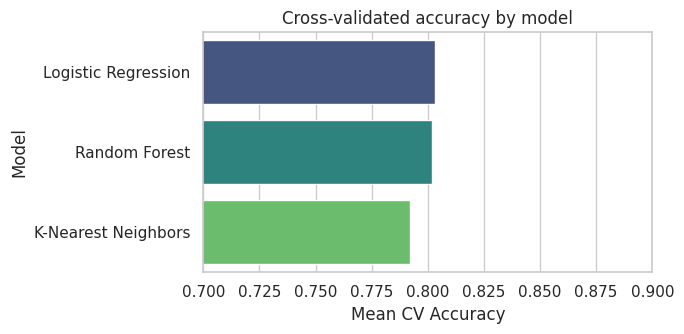

In [11]:
plt.figure(figsize=(7, 3.5))
sns.barplot(data=results, x="Mean CV Accuracy", y="Model", palette="viridis")
plt.xlim(0.7, 0.9)
plt.title("Cross-validated accuracy by model")
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning (Random Forest)

A small grid search with cross-validation, run on the **training set only**.

In [12]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE)),
])
param_grid = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [4, 6, 8, None],
    "clf__min_samples_leaf": [1, 2, 4],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

Best parameters: {'clf__max_depth': 6, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Best CV accuracy: 0.8301


## 9. Final evaluation on the held-out test set

The test set has not been touched until now, so this is an honest estimate of performance on unseen passengers.

Test accuracy: 0.8045

                 precision    recall  f1-score   support

Did not survive       0.79      0.93      0.85       110
       Survived       0.84      0.61      0.71        69

       accuracy                           0.80       179
      macro avg       0.82      0.77      0.78       179
   weighted avg       0.81      0.80      0.80       179



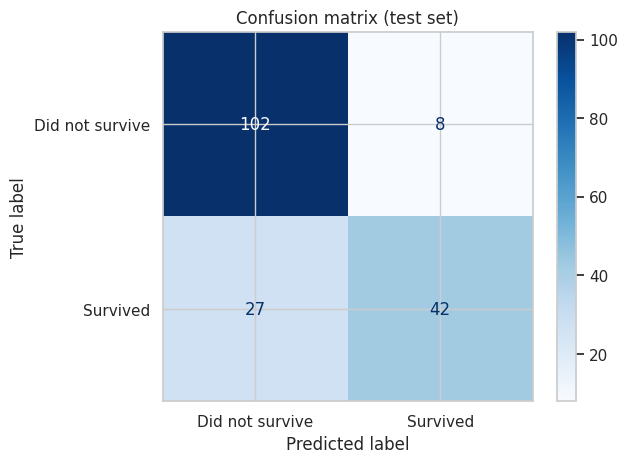

In [13]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Did not survive", "Survived"], cmap="Blues"
)
plt.title("Confusion matrix (test set)")
plt.show()

## 10. Feature importance

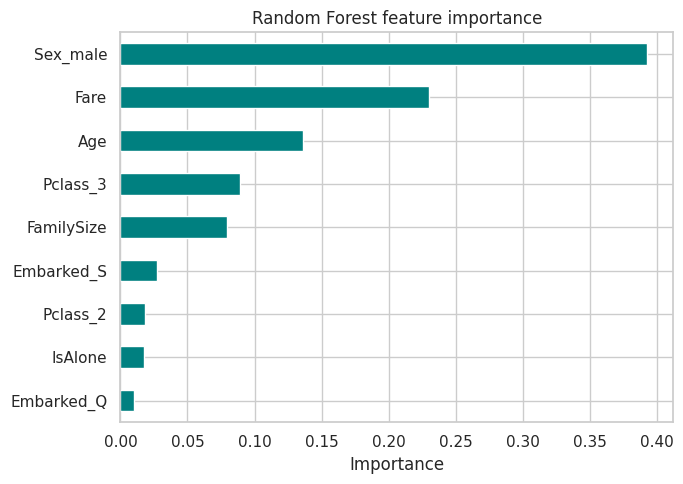

,0
Sex_male,0.393
Fare,0.230
Age,0.136
Pclass_3,0.089
FamilySize,0.079


In [14]:
prep = best_model.named_steps["prep"]
rf = best_model.named_steps["clf"]
feature_names = prep.get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]

importance = (pd.Series(rf.feature_importances_, index=feature_names)
              .sort_values(ascending=True))

plt.figure(figsize=(7, 5))
importance.plot(kind="barh", color="teal")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).head(5).round(3)

## 11. Save the model and test reloading it

In [15]:
with open("titanic_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("titanic_model.pkl", "rb") as f:
    loaded = pickle.load(f)

# Example: a 28-year-old woman, 1st class, paid 80, travelling with 1 relative
example = pd.DataFrame([{
    "Pclass": 1, "Sex": "female", "Age": 28, "Fare": 80.0,
    "Embarked": "S", "FamilySize": 2, "IsAlone": 0,
}])
prob = loaded.predict_proba(example)[0, 1]
print(f"Predicted survival probability: {prob:.1%}")

Predicted survival probability: 94.7%


## 12. Conclusion

- Before tuning, Logistic Regression (80.3%), Random Forest (80.2%) and KNN (79.2%) scored almost the same in 5-fold CV, so a simple model is already competitive on this small dataset.
- The tuned Random Forest (`max_depth=6`) reached **83.0% CV accuracy** on the training set and **80.5% accuracy on the held-out test set**.
- **Sex** was by far the most important feature (about 39%), followed by **Fare**, **Age**, third class and family size, which matches the "women and children first" pattern seen in the EDA.
- The model is better at spotting who did *not* survive (recall 0.93) than who did (recall 0.61), so it misses many survivors.
- **Limitations:** only 891 rows, many missing ages, and a test set of just 179 passengers, so the test accuracy could easily vary by a few points. Further gains might come from extracting titles (Mr/Mrs/Miss) from names and using cabin deck information.